# Previsão de Demanda com Variáveis Externas — Quantum Commerce

Trabalho final · Machine Learning · MBA AI Engineering & Multi-Agents (FIAP)

**Problema:** antecipar picos de venda por loja/região para reduzir custos logísticos da Quantum Commerce.

**Dados (proxy):** Walmart Dataset (45 lojas, vendas semanais 2010–2012).

## Etapa 0 · Setup

Objetivo: notebook rodando com os dados carregados.

In [2]:
# Instala as bibliotecas no MESMO kernel que está rodando o notebook
%pip install -q pandas numpy matplotlib seaborn scikit-learn kagglehub

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.float_format", "{:,.2f}".format)
print("pandas", pd.__version__, "| sklearn", sklearn.__version__)

pandas 2.2.3 | sklearn 1.6.1


In [4]:
from pathlib import Path
import kagglehub

# Fallback: se o kagglehub travar, baixe o CSV no site e salve em data/Walmart.csv
LOCAL_CSV = Path("data/Walmart.csv")

if LOCAL_CSV.exists():
    csv_path = LOCAL_CSV
else:
    dataset_dir = Path(kagglehub.dataset_download("rutuspatel/walmart-dataset-retail"))
    csv_path = next(dataset_dir.glob("*.csv"))

print(csv_path)

100%|██████████| 122k/122k [00:00<00:00, 25.8MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/rutuspatel/walmart-dataset-retail/versions/1/Walmart_Store_sales.csv


In [5]:
df = pd.read_csv(csv_path)
print(df.shape)
df.head()

(6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.90",0,42.31,2.57,211.10,8.11
1,1,12-02-2010,"1,641,957.44",1,38.51,2.55,211.24,8.11
2,1,19-02-2010,"1,611,968.17",0,39.93,2.51,211.29,8.11
3,1,26-02-2010,"1,409,727.59",0,46.63,2.56,211.32,8.11
4,1,05-03-2010,"1,554,806.68",0,46.50,2.62,211.35,8.11


## Etapa 1 · Raio-X do dataset

Objetivo: entender formato e qualidade dos dados antes de qualquer gráfico.

**Dados em painel:** várias séries temporais lado a lado, uma por loja (como métricas de 45 serviços no mesmo dashboard).

In [6]:
# Tipos, nulos e duplicados
df.info()
print("\nLinhas duplicadas:", df.duplicated().sum())
print("Pares (Store, Date) duplicados:", df.duplicated(subset=["Store", "Date"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB

Linhas duplicadas: 0
Pares (Store, Date) duplicados: 0


In [7]:
# Estatísticas básicas (transposto: uma linha por coluna)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Store,"6,435.00",23.00,12.99,1.00,12.00,23.00,34.00,45.00
Weekly_Sales,"6,435.00","1,046,964.88","564,366.62","209,986.25","553,350.10","960,746.04","1,420,158.66","3,818,686.45"
Holiday_Flag,"6,435.00",0.07,0.26,0.00,0.00,0.00,0.00,1.00
Temperature,"6,435.00",60.66,18.44,-2.06,47.46,62.67,74.94,100.14
Fuel_Price,"6,435.00",3.36,0.46,2.47,2.93,3.44,3.73,4.47
CPI,"6,435.00",171.58,39.36,126.06,131.74,182.62,212.74,227.23
Unemployment,"6,435.00",8.00,1.88,3.88,6.89,7.87,8.62,14.31


In [8]:
# Conversão definitiva com o formato dia-mês-ano explícito
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

# Ordena por loja e data: pré-requisito para os lags da Etapa 3
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
df.dtypes

,0
Store,int64
Date,datetime64[ns]
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


In [9]:
# Temperatura de °F para °C (só muda a leitura, não o que o modelo aprende)
# Substitui a coluna original para não ter duas features idênticas
# O if deixa a célula idempotente: rodar de novo não converte duas vezes
if "Temperature" in df.columns:
    df["Temperature_C"] = ((df["Temperature"] - 32) * 5 / 9).round(2)
    df = df.drop(columns="Temperature")

df["Temperature_C"].describe()

,Temperature_C
count,"6,435.00"
mean,15.92
std,10.25
min,-18.92
25%,8.59
50%,17.04
75%,23.86
max,37.86


In [10]:
# Estatísticas básicas depois de converter a temperatura (transposto: uma linha por coluna)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Store,"6,435.00",23.00,1.00,12.00,23.00,34.00,45.00,12.99
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,"6,435.00","1,046,964.88","209,986.25","553,350.10","960,746.04","1,420,158.66","3,818,686.45","564,366.62"
Holiday_Flag,"6,435.00",0.07,0.00,0.00,0.00,0.00,1.00,0.26
Fuel_Price,"6,435.00",3.36,2.47,2.93,3.44,3.73,4.47,0.46
CPI,"6,435.00",171.58,126.06,131.74,182.62,212.74,227.23,39.36
Unemployment,"6,435.00",8.00,3.88,6.89,7.87,8.62,14.31,1.88
Temperature_C,"6,435.00",15.92,-18.92,8.59,17.04,23.86,37.86,10.25


In [11]:
# Quantas lojas, quantas semanas por loja e qual período cada uma cobre
periodo = df.groupby("Store")["Date"].agg(["count", "min", "max"])

print("Lojas:", df["Store"].nunique())
print("Semanas por loja (valores distintos):", periodo["count"].unique())
print("Datas de início distintas:", periodo["min"].nunique(), "| de fim:", periodo["max"].nunique())
print("Período:", df["Date"].min().date(), "→", df["Date"].max().date())
print("Semanas com feriado:", df.loc[df["Holiday_Flag"] == 1, "Date"].nunique())

Lojas: 45
Semanas por loja (valores distintos): [143]
Datas de início distintas: 1 | de fim: 1
Período: 2010-02-05 → 2012-10-26
Semanas com feriado: 10


In [12]:
# A série é realmente semanal e sem buracos? Diferença entre datas consecutivas de cada loja
intervalos = df.groupby("Store")["Date"].diff().dropna()
intervalos.value_counts()

,count
Date,
7 days,6390


## Etapa 2 · Explorando o comportamento no tempo

Vendas totais por semana

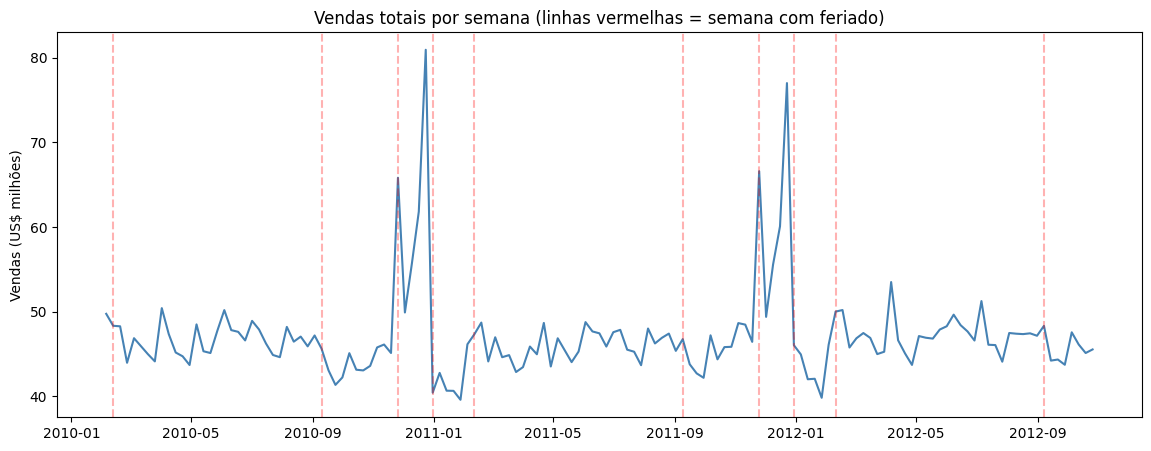

In [13]:
# Vendas totais da rede por semana (soma das 45 lojas)
total_semanal = df.groupby("Date").agg(
    Weekly_Sales=("Weekly_Sales", "sum"),
    Holiday_Flag=("Holiday_Flag", "max"),  # o feriado é o mesmo para todas as lojas
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(total_semanal.index, total_semanal["Weekly_Sales"] / 1e6, color="steelblue")

# Linha vertical em cada semana de feriado
for data in total_semanal.index[total_semanal["Holiday_Flag"] == 1]:
    ax.axvline(data, color="red", alpha=0.3, linestyle="--")

ax.set_title("Vendas totais por semana (linhas vermelhas = semana com feriado)")
ax.set_ylabel("Vendas (US$ milhões)")
plt.show()

Lojas lado a lado

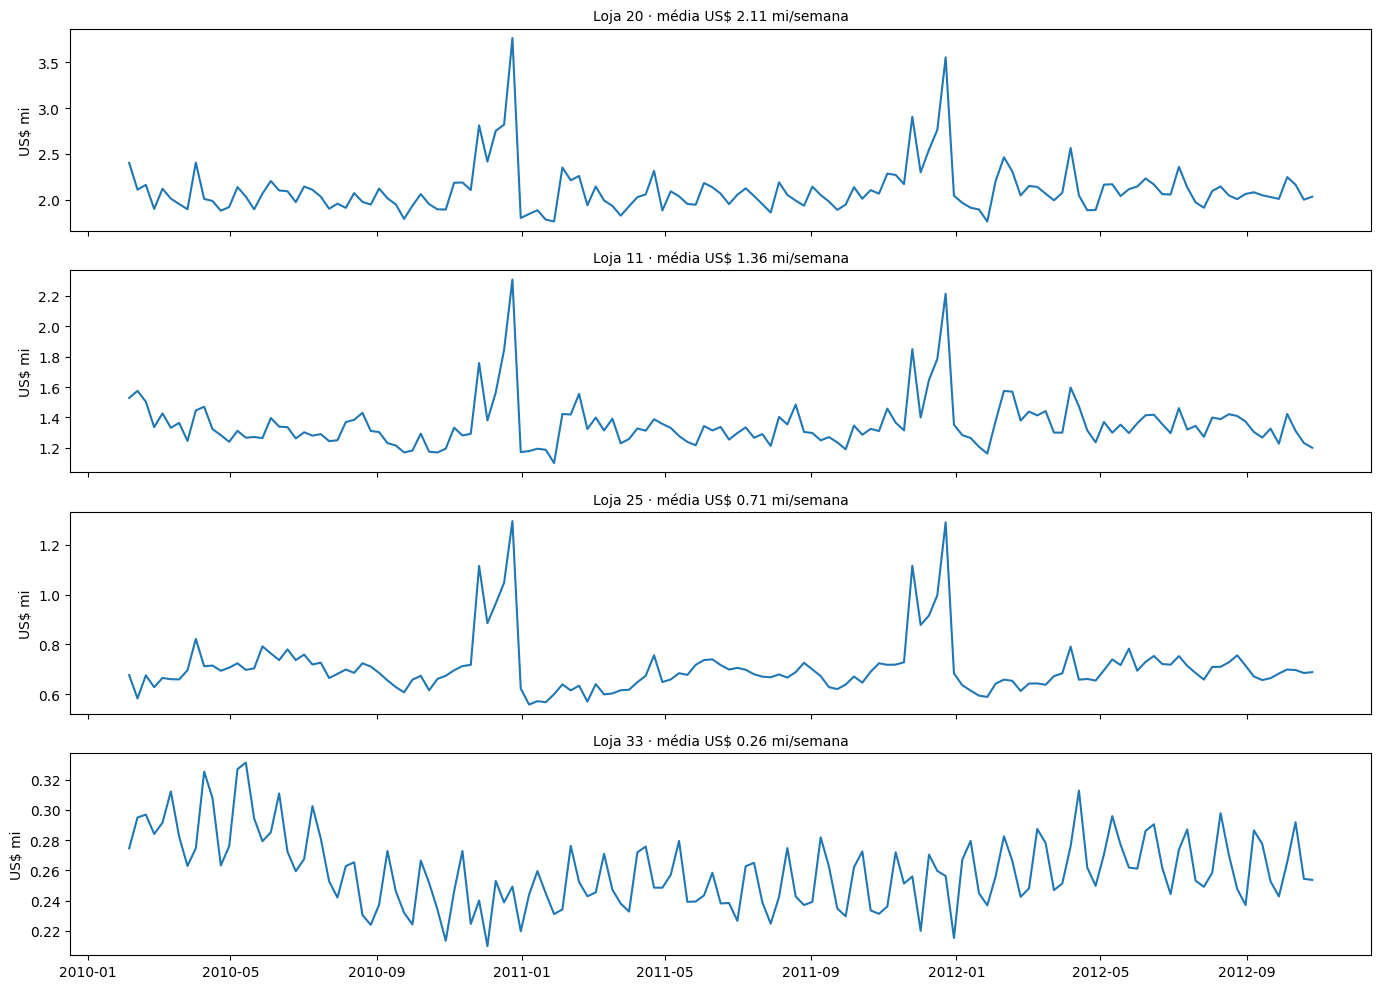

In [14]:
# Escolhe 4 lojas pela venda média: a maior, a menor e duas intermediárias
media_loja = df.groupby("Store")["Weekly_Sales"].mean().sort_values()
lojas = [media_loja.index[-1], media_loja.index[30], media_loja.index[15], media_loja.index[0]]

fig, axes = plt.subplots(len(lojas), 1, figsize=(14, 10), sharex=True)
for ax, loja in zip(axes, lojas):
    serie = df[df["Store"] == loja]
    ax.plot(serie["Date"], serie["Weekly_Sales"] / 1e6)
    ax.set_title(f"Loja {loja} · média US$ {media_loja[loja] / 1e6:.2f} mi/semana", fontsize=10)
    ax.set_ylabel("US$ mi")

plt.tight_layout()
plt.show()


Venda média semanal por loja

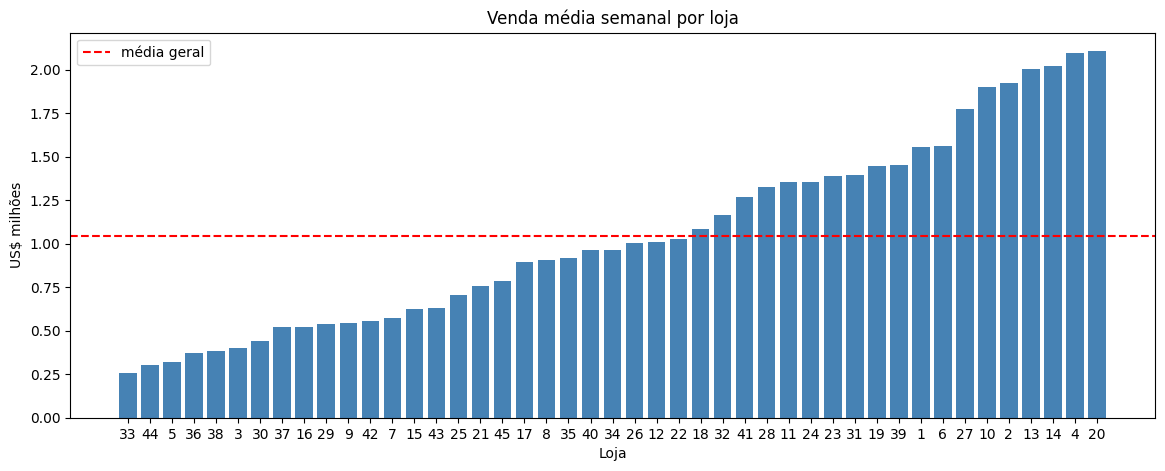

In [15]:
# Venda média semanal por loja, da menor para a maior (reaproveita media_loja da célula anterior)
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(media_loja.index.astype(str), media_loja.values / 1e6, color="steelblue")
ax.axhline(media_loja.mean() / 1e6, color="red", linestyle="--", label="média geral")

ax.set_title("Venda média semanal por loja")
ax.set_xlabel("Loja")
ax.set_ylabel("US$ milhões")
ax.legend()
plt.show()


Venda relativa: semana / média da própria loja (remove o efeito do tamanho da loja)

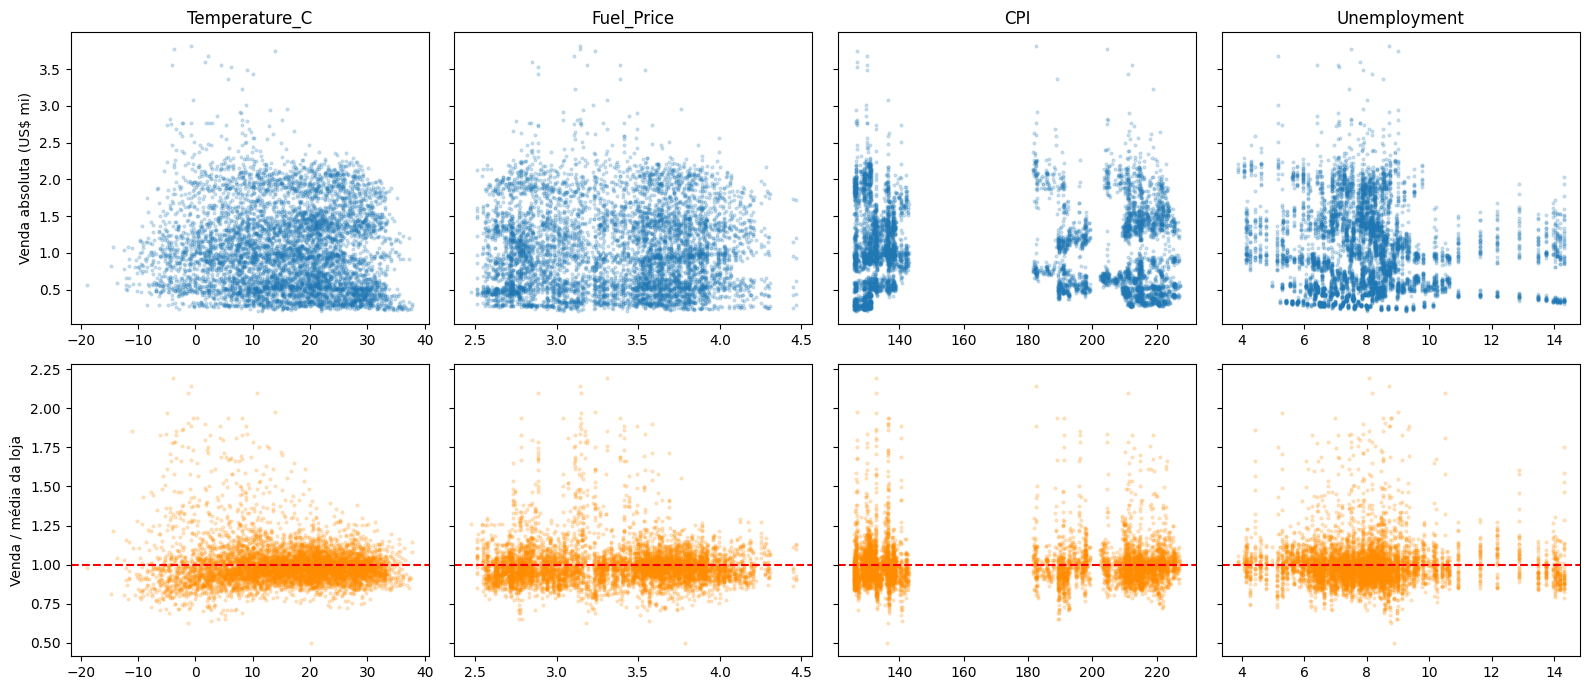

In [16]:
# Venda relativa: semana / média da própria loja (remove o efeito do tamanho da loja)
venda_rel = df["Weekly_Sales"] / df.groupby("Store")["Weekly_Sales"].transform("mean")

externas = ["Temperature_C", "Fuel_Price", "CPI", "Unemployment"]

fig, axes = plt.subplots(2, len(externas), figsize=(16, 7), sharey="row")
for j, col in enumerate(externas):
    # Linha de cima: venda absoluta (o que NÃO fazer)
    axes[0, j].scatter(df[col], df["Weekly_Sales"] / 1e6, s=4, alpha=0.2)
    axes[0, j].set_title(col)
    # Linha de baixo: venda relativa à média da loja
    axes[1, j].scatter(df[col], venda_rel, s=4, alpha=0.2, color="darkorange")
    axes[1, j].axhline(1, color="red", linestyle="--")

axes[0, 0].set_ylabel("Venda absoluta (US$ mi)")
axes[1, 0].set_ylabel("Venda / média da loja")
plt.tight_layout()
plt.show()


Correlação de cada variável com a venda absoluta e com a venda relativa à média da loja

               vs Weekly_Sales  vs venda relativa
Holiday_Flag              0.04               0.14
Temperature_C            -0.06              -0.08
Fuel_Price                0.01              -0.03
CPI                      -0.07               0.00
Unemployment             -0.11              -0.02


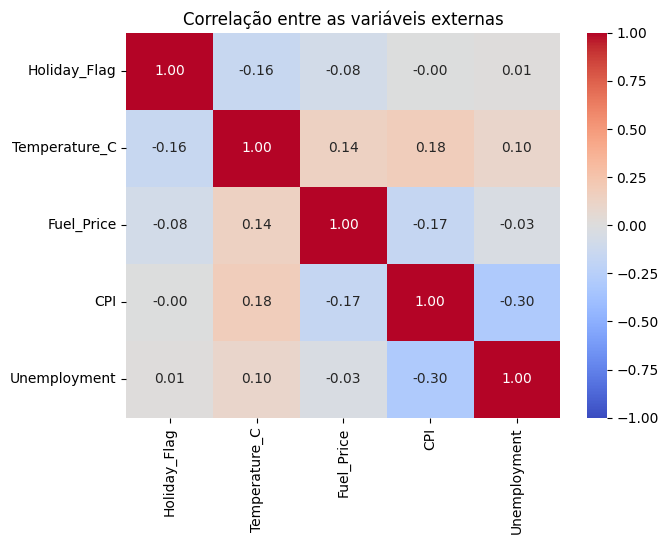

In [17]:
# Correlação de cada variável com a venda absoluta e com a venda relativa à média da loja
cols = ["Holiday_Flag", "Temperature_C", "Fuel_Price", "CPI", "Unemployment"]
corr = pd.DataFrame({
    "vs Weekly_Sales": df[cols].corrwith(df["Weekly_Sales"]),
    "vs venda relativa": df[cols].corrwith(venda_rel),
})
print(corr.round(3))

# Matriz completa entre as variáveis externas (procura variáveis redundantes)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação entre as variáveis externas")
plt.show()


### Conclusões da Etapa 2
- **Sazonalidade anual forte:** dois picos por ano (Black Friday e semana pré-Natal), seguidos de queda em janeiro.
- **`Holiday_Flag` é imprecisa:** marca Thanksgiving corretamente, mas a flag de Natal cai na semana *após* o pico; Super Bowl e Labor Day quase não afetam vendas.
- **Tendência fraca:** leve alta em 2012, pequena perto da sazonalidade.
- **Escala varia ~8x entre lojas** (US$ 0,26 mi a 2,11 mi/semana), de forma quase contínua. 19 lojas acima da média e 26 abaixo.
- **Lojas atípicas:** a loja 33 não tem pico de fim de ano e tem um ciclo mensal (~4 semanas). É candidata a erro sistemático num modelo global.
- **Variáveis externas têm relação linear fraca** (|r| ≤ 0,14 na venda relativa). A temperatura parece relacionada só porque o frio coincide com o fim de ano (confusão com o calendário).
- **CPI e Unemployment funcionam como "identificador de região"** (ilhas). Risco de virarem um proxy do ID da loja nas árvores.
- **Hipóteses para testar:** `lag_52` e a semana do ano devem superar `Holiday_Flag` e a temperatura (etapas 3 e 6); a loja 33 deve ter erro alto (etapa 9).


## Etapa 3 · Lags: o passado como feature

Objetivo: criar as primeiras features a partir do próprio histórico, ainda sem modelo.

**Lag:** usar o valor passado da série como informação para prever o presente (como usar o tráfego da semana passada para planejar a capacidade desta).

**Armadilhas:** (1) lag sem `groupby("Store")` mistura lojas; (2) média móvel sem `shift(1)` inclui a semana atual (vazamento).

### 3a · Criando as features

In [18]:
# Lags e média móvel, sempre por loja (df já está ordenado por Store e Date na Etapa 1)
g = df.groupby("Store")["Weekly_Sales"]

df["lag_1"] = g.shift(1)    # semana anterior
df["lag_52"] = g.shift(52)  # mesma semana do ano anterior

# shift(1) ANTES do rolling: a janela de 4 semanas termina na semana passada
df["ma_4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())

df[df["Store"] == 1][["Date", "Weekly_Sales", "lag_1", "lag_52", "ma_4"]].head(8)

,Date,Weekly_Sales,lag_1,lag_52,ma_4
0,2010-02-05,"1,643,690.90",NaN,NaN,NaN
1,2010-02-12,"1,641,957.44","1,643,690.90",NaN,NaN
2,2010-02-19,"1,611,968.17","1,641,957.44",NaN,NaN
3,2010-02-26,"1,409,727.59","1,611,968.17",NaN,NaN
4,2010-03-05,"1,554,806.68","1,409,727.59",NaN,"1,576,836.02"
5,2010-03-12,"1,439,541.59","1,554,806.68",NaN,"1,554,614.97"
6,2010-03-19,"1,472,515.79","1,439,541.59",NaN,"1,504,011.01"
7,2010-03-26,"1,404,429.92","1,472,515.79",NaN,"1,469,147.91"


### 3b · Custo dos lags e correlação

In [19]:
# Quantas linhas ficam sem valor em cada feature, e quanto dos dados sobra
features_lag = ["lag_1", "lag_52", "ma_4"]
print(df[features_lag].isna().sum())

completas = df.dropna(subset=features_lag)
print(f"\nLinhas completas: {len(completas)} de {len(df)} ({len(completas) / len(df):.0%})")

lag_1       45
lag_52    2340
ma_4       180
dtype: int64

Linhas completas: 4095 de 6435 (64%)


Correlação das features com a venda atual (só linhas completas, para comparar no mesmo conjunto)

In [20]:
# Correlação absoluta (infla pelo tamanho da loja) e relativa (venda / média da loja)
media_loja_c = completas.groupby("Store")["Weekly_Sales"].transform("mean")
rel = completas[features_lag + ["Weekly_Sales"]].div(media_loja_c, axis=0)

pd.DataFrame({
    "absoluta": completas[features_lag].corrwith(completas["Weekly_Sales"]),
    "relativa à loja": rel[features_lag].corrwith(rel["Weekly_Sales"]),
}).round(3)

,absoluta,relativa à loja
lag_1,0.96,0.43
lag_52,0.99,0.78
ma_4,0.97,0.41


### Conclusões da Etapa 3
- **Features criadas:** `lag_1`, `lag_52` e `ma_4`, sempre por loja e com `shift(1)` na média móvel (sem vazamento).
- **Custo do `lag_52`:** 2.340 linhas sem valor (45 lojas × 52 semanas). Sobram 4.095 de 6.435 (64%), cerca de 91 semanas por loja.
- **Correlação absoluta (0,96 a 0,99) é enganosa:** reflete o tamanho da loja, não a capacidade de prever.
- **Correlação relativa à loja:** `lag_52` = 0,78 contra 0,43 (`lag_1`) e 0,41 (`ma_4`). A sazonalidade anual domina a variação dentro de cada loja.
- **`ma_4` não superou `lag_1`:** suavizar não ajuda quando o que importa é o salto sazonal.
- **Ressalvas:** correlação é linear e calculada só onde o `lag_52` existe. Pico que se desloca de semana de um ano para o outro enfraquece o `lag_52`. Testar na Etapa 5.
- **Alternativa ao custo dos dados:** manter linhas sem `lag_52` com modelos que aceitam `NaN` (ex: `HistGradientBoostingRegressor`, Etapa 7).

## Etapa 4 · Split temporal e baselines

Objetivo: definir como medir e qual é a régua mínima que qualquer modelo precisa vencer.

**Split temporal:** treino no passado, teste no futuro (split aleatório deixaria o modelo olhar o futuro).

**Baseline:** regra simples que o modelo precisa vencer.

**Atenção:** as últimas 30 semanas (abr–out/2012) não incluem Black Friday nem Natal.

### 4a · Split temporal

In [21]:
# Corte por data: as últimas 30 semanas (datas distintas) viram teste
N_TESTE = 30
datas = np.sort(df["Date"].unique())
data_corte = datas[-N_TESTE]  # primeira semana do teste

treino = df[df["Date"] < data_corte]
teste = df[df["Date"] >= data_corte]

print("Treino:", treino["Date"].min().date(), "→", treino["Date"].max().date(), "|", len(treino), "linhas")
print("Teste: ", teste["Date"].min().date(), "→", teste["Date"].max().date(), "|", len(teste), "linhas")
print("Semanas de teste:", teste["Date"].nunique(), "| feriados no teste:", teste.loc[teste["Holiday_Flag"] == 1, "Date"].nunique())
print("Treino termina antes do teste começar:", treino["Date"].max() < teste["Date"].min())

Treino: 2010-02-05 → 2012-03-30 | 5085 linhas
Teste:  2012-04-06 → 2012-10-26 | 1350 linhas
Semanas de teste: 30 | feriados no teste: 1
Treino termina antes do teste começar: True


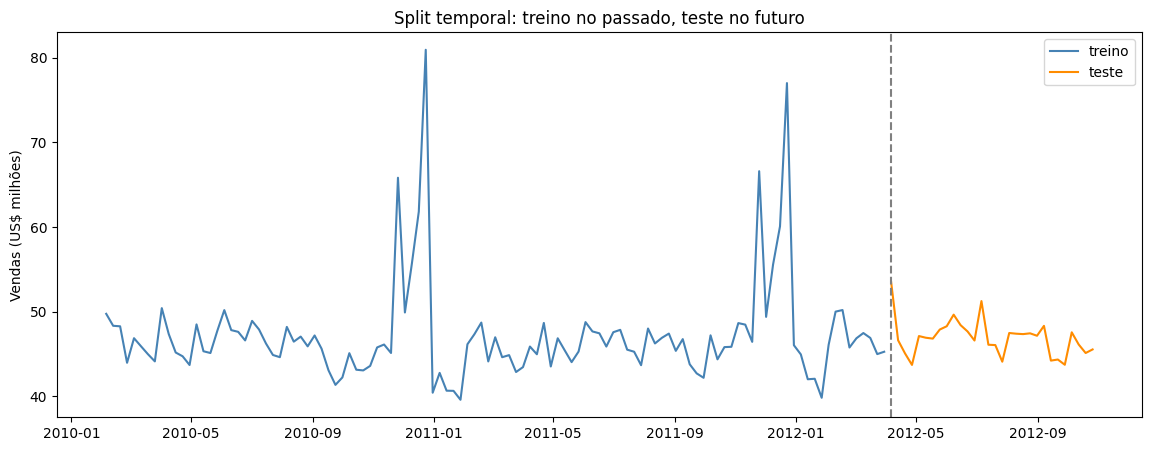

In [22]:
# Visualiza o corte nas vendas totais da rede
tot = df.groupby("Date")["Weekly_Sales"].sum() / 1e6
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(tot[tot.index < data_corte], color="steelblue", label="treino")
ax.plot(tot[tot.index >= data_corte], color="darkorange", label="teste")
ax.axvline(data_corte, color="gray", linestyle="--")
ax.set_title("Split temporal: treino no passado, teste no futuro")
ax.set_ylabel("Vendas (US$ milhões)")
ax.legend()
plt.show()

### 4b · Métricas, baselines e tabela de resultados

**MAE:** erro médio absoluto em US$. **WAPE:** soma dos erros absolutos / soma das vendas reais (erro como % do volume).

**Baselines:** "repete a semana passada" (`lag_1`) e "repete o ano passado" (`lag_52`).

In [23]:
# Métricas: calculadas sobre TODAS as linhas do teste juntas (lojas misturadas)
def mae(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def wape(y, y_pred):
    return np.sum(np.abs(y - y_pred)) / np.sum(y)

# Sanidade: previsão perfeita deve dar erro zero; chutar 0 deve dar WAPE = 100%
y_demo = np.array([100.0, 200.0, 300.0])
print("perfeita:", mae(y_demo, y_demo), wape(y_demo, y_demo))
print("chute zero:", mae(y_demo, y_demo * 0), wape(y_demo, y_demo * 0))

perfeita: 0.0 0.0
chute zero: 200.0 1.0


In [24]:
# Tabela de resultados: o fio condutor do trabalho (cada modelo adiciona uma linha)
resultados = pd.DataFrame(columns=["modelo", "MAE", "WAPE"])

def registrar(nome, y, y_pred):
    # Substitui a linha se o nome já existir (célula idempotente)
    global resultados
    resultados = resultados[resultados["modelo"] != nome]
    resultados.loc[len(resultados)] = [nome, mae(y, y_pred), wape(y, y_pred)]

y_teste = teste["Weekly_Sales"]

# Os baselines não treinam nada: a "previsão" é a própria feature
print("NaN nas features do teste:", teste[["lag_1", "lag_52"]].isna().sum().to_dict())
registrar("Baseline: repete semana passada (lag_1)", y_teste, teste["lag_1"])
registrar("Baseline: repete ano passado (lag_52)", y_teste, teste["lag_52"])

resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

NaN nas features do teste: {'lag_1': 0, 'lag_52': 0}


,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%


### Conclusões da Etapa 4
- **Split temporal:** treino de 05/02/2010 a 30/03/2012 (113 semanas, 5.085 linhas) e teste de 06/04/2012 a 26/10/2012 (30 semanas, 1.350 linhas).
- **Limitação do teste:** não inclui Black Friday nem Natal e tem só 1 semana de feriado (Labor Day). É um teste mais fácil que o uso real. A Etapa 9 (`TimeSeriesSplit`) deve cobrir um pico.
- **Baselines (régua mínima):** repetir a semana passada = MAE US$ 58,6 mil e WAPE 5,6%. Repetir o ano passado = MAE US$ 59,3 mil e WAPE 5,7%. Quase empatam.
- **Hipótese para a Etapa 5:** os dois erram em lugares diferentes, então combiná-los (regressão linear) deve vencer ambos.
- **Por que 30 semanas:** equilíbrio entre confiabilidade da métrica (teste maior) e dados para treinar (principalmente com o `lag_52`). Poucas semanas deixam a métrica ruidosa, e muitas deixam o treino ralo.

## Etapa 5 · Primeiro modelo: regressão linear só com lags

Objetivo: treinar o primeiro modelo de verdade e comparar com os baselines.

**Regressão linear:** um peso por feature, somados com um intercepto.

### 5a · Treino e avaliação

In [25]:
from sklearn.linear_model import LinearRegression

feat_lags = ["lag_1", "lag_52", "ma_4"]

# Treino só com linhas completas (LinearRegression não aceita NaN); o teste já está completo
treino_c = treino.dropna(subset=feat_lags)
print("Linhas de treino usadas:", len(treino_c), "de", len(treino))

X_treino, y_treino = treino_c[feat_lags], treino_c["Weekly_Sales"]
X_teste = teste[feat_lags]

modelo_lin = LinearRegression().fit(X_treino, y_treino)
pred_lin = modelo_lin.predict(X_teste)

registrar("Regressão linear (lags)", y_teste, pred_lin)
resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

Linhas de treino usadas: 2745 de 5085


,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%
2,Regressão linear (lags),"47,158",4.5%


### 5b · Real vs previsto, coeficientes e onde o modelo erra

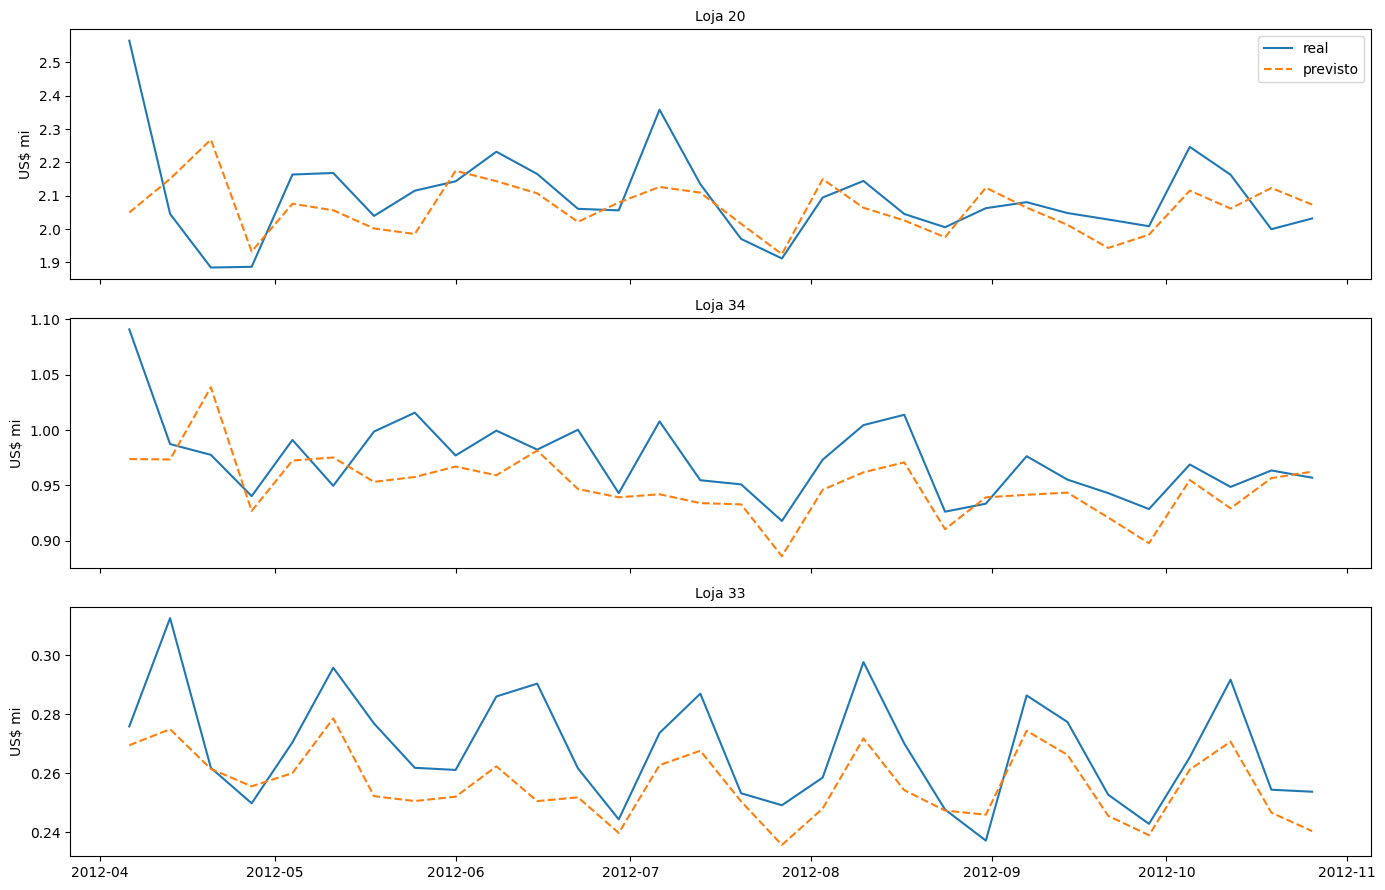

In [26]:
# Real vs previsto no teste: a maior loja, uma intermediária e a loja 33 (atípica)
teste_pred = teste.assign(pred=pred_lin)
lojas_plot = [media_loja.index[-1], media_loja.index[22], 33]

fig, axes = plt.subplots(len(lojas_plot), 1, figsize=(14, 9), sharex=True)
for ax, loja in zip(axes, lojas_plot):
    s = teste_pred[teste_pred["Store"] == loja]
    ax.plot(s["Date"], s["Weekly_Sales"] / 1e6, label="real")
    ax.plot(s["Date"], s["pred"] / 1e6, label="previsto", linestyle="--")
    ax.set_title(f"Loja {loja}", fontsize=10)
    ax.set_ylabel("US$ mi")
axes[0].legend()
plt.tight_layout()
plt.show()

In [27]:
# Quanto o modelo confia em cada feature? (pesos em dólares por dólar da feature)
print("Intercepto:", round(modelo_lin.intercept_))
pd.Series(modelo_lin.coef_, index=feat_lags).round(3)

Intercepto: -174


,0
lag_1,0.13
lag_52,0.72
ma_4,0.16


In [28]:
# Onde o modelo erra mais? WAPE por loja (as 5 piores) e semana de feriado vs normal
def wape_grupo(d):
    return np.sum(np.abs(d["Weekly_Sales"] - d["pred"])) / np.sum(d["Weekly_Sales"])

por_loja = teste_pred.groupby("Store").apply(wape_grupo, include_groups=False).sort_values(ascending=False)
print("5 piores lojas (WAPE):")
print(por_loja.head(5).map("{:.1%}".format))
print("\nMediana entre lojas:", f"{por_loja.median():.1%}")

print("\nFeriado vs normal:")
print(teste_pred.groupby("Holiday_Flag").apply(wape_grupo, include_groups=False).map("{:.1%}".format))

5 piores lojas (WAPE):
Store
36    14.6%
14    12.0%
38     7.8%
44     7.5%
39     6.7%
dtype: object

Mediana entre lojas: 4.3%

Feriado vs normal:
Holiday_Flag
0    4.5%
1    4.7%
dtype: object


### Conclusões da Etapa 5
- **Resultado:** a regressão linear (lags) venceu os dois baselines: MAE US$ 47,2 mil e WAPE 4,5%, contra 5,6% do melhor baseline (queda de ~20% no erro).
- **O que o modelo aprendeu:** ponderar as fontes. Pesos: `lag_52` = 0,72, `ma_4` = 0,16, `lag_1` = 0,13 (soma ≈ 1, intercepto ≈ 0). Usa ~72% do ano passado (sazonalidade) e ~29% do nível recente (ajuste de curto prazo). Cada baseline usava só uma das duas.
- **Feriado móvel (Páscoa):** nas lojas 20 e 34 o pico real ficou em 06/04/2012 e o previsto 2 semanas depois, porque a Páscoa foi em 08/04/2012 e em 24/04/2011. O `lag_52` alinha pela semana do ano, não pelo evento, e a `Holiday_Flag` não marca a Páscoa. Limitação a registrar.
- **Possível viés de crescimento (hipótese):** nas lojas 33 e 34 o previsto fica quase sempre abaixo do real. Checar com erro médio com sinal.
- **Erro por loja:** mediana 4,3%, mas as lojas 36 (14,6%) e 14 (12,0%) puxam a média. A loja 33 (atípica na Etapa 2) não está entre as 5 piores. Causa das lojas 36 e 14 em aberto para a Etapa 9.
- **Feriado vs normal:** 4,7% contra 4,5%, mas o teste tem uma só semana de feriado. Sem conclusão.

## Etapa 6 · Adicionando variáveis externas

Objetivo: testar se os fatores externos ajudam de verdade.

**Ablação:** adicionar ou tirar um grupo de features e medir o impacto no teste.

**Pegadinha do futuro:** no teste usamos a temperatura/CPI reais da semana; na vida real seriam previsões (resultado otimista).

**Páscoa:** não entra como feature (fica como limitação).

### 6a · Ablação por grupos

In [29]:
# Calendário: mês em dummies (0/1). Mês como número seria tratado como linear (dez > fev).
# É determinístico (vem só da data), então criar no df inteiro não vaza informação.
df = df.drop(columns=[c for c in df.columns if c.startswith("mes_")])  # idempotente
df = pd.concat([df, pd.get_dummies(df["Date"].dt.month, prefix="mes", dtype=float)], axis=1)

# Refaz o split (mesmo corte de data) para treino/teste terem as novas colunas
treino = df[df["Date"] < data_corte]
teste = df[df["Date"] >= data_corte]
assert len(treino) == 5085 and len(teste) == 1350

feat_lags = ["lag_1", "lag_52", "ma_4"]
feat_externas = ["Holiday_Flag", "Temperature_C", "Fuel_Price", "CPI", "Unemployment"]
feat_mes = [c for c in df.columns if c.startswith("mes_")]
print("Dummies de mês:", len(feat_mes))

Dummies de mês: 12


In [30]:
# Treina uma regressão linear com um conjunto de features e registra na tabela
def avaliar_linear(nome, feats):
    tr = treino.dropna(subset=feat_lags)  # mesmas linhas de treino em todas as variações
    m = LinearRegression().fit(tr[feats], tr["Weekly_Sales"])
    pred = m.predict(teste[feats])
    registrar(nome, y_teste, pred)
    return m

avaliar_linear("Linear: lags + externas", feat_lags + feat_externas)
avaliar_linear("Linear: lags + calendário (mês)", feat_lags + feat_mes)
avaliar_linear("Linear: lags + externas + calendário", feat_lags + feat_externas + feat_mes)

resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%
2,Regressão linear (lags),"47,158",4.5%
3,Linear: lags + externas,"47,585",4.6%
4,Linear: lags + calendário (mês),"51,562",4.9%
5,Linear: lags + externas + calendário,"50,295",4.8%


### 6b · Ablação variável por variável

In [31]:
# Adiciona UMA variável por vez aos lags e mede o WAPE (sem poluir a tabela principal)
def wape_linear(feats):
    tr = treino.dropna(subset=feat_lags)
    m = LinearRegression().fit(tr[feats], tr["Weekly_Sales"])
    return wape(y_teste, m.predict(teste[feats]))

base = wape_linear(feat_lags)
linhas = [("(só lags)", base, 0.0)]
for col in feat_externas:
    w = wape_linear(feat_lags + [col])
    linhas.append((f"+ {col}", w, (w - base) * 100))
w = wape_linear(feat_lags + feat_mes)
linhas.append(("+ mês (12 dummies)", w, (w - base) * 100))

pd.DataFrame(linhas, columns=["features", "WAPE", "Δ vs só lags (p.p.)"]).style.format(
    {"WAPE": "{:.2%}", "Δ vs só lags (p.p.)": "{:+.2f}"})

,features,WAPE,Δ vs só lags (p.p.)
0,(só lags),4.52%,+0.00
1,+ Holiday_Flag,4.60%,+0.07
2,+ Temperature_C,4.58%,+0.05
3,+ Fuel_Price,4.67%,+0.15
4,+ CPI,4.54%,+0.02
5,+ Unemployment,4.46%,-0.06
6,+ mês (12 dummies),4.94%,+0.42


### Conclusões da Etapa 6
- **Ablação por grupos (WAPE no teste):** só lags 4,5% · + externas 4,6% · + mês 4,9% · + externas + mês 4,8%. Nenhuma variação venceu o modelo só com lags.
- **Variáveis externas:** não melhoraram o WAPE (+0,1 p.p. com as 5 juntas, dentro do ruído de um teste de 30 semanas). Isso confirma a relação fraca vista na Etapa 2.
- **Uma a uma (Δ p.p. vs só lags):** `Unemployment` −0,06 (único que melhorou, dentro do ruído), `CPI` +0,02, `Temperature_C` +0,05, `Holiday_Flag` +0,07, `Fuel_Price` +0,15.
- **`Holiday_Flag`:** a flag é imprecisa (Natal na semana errada) e o teste tem só uma semana de feriado (Labor Day).
- **Mês em dummies:** piorou 0,42 p.p. Hipótese: cada mês de abr–out aparece em um único ano no treino, e o modelo decora 2011. O `lag_52` já carrega a sazonalidade.
- **Ressalvas:** o teste usa as variáveis externas reais da semana (cenário otimista; na prática seriam previsões). O modelo linear só captura efeitos aditivos; interações (ex: temperatura × época) ficam para as árvores da Etapa 7.
- **Lição para o TCC:** testar cada variável por ablação em vez de assumir que ajuda. No agro o clima é motor causal da safra e os lags não o contêm, então o resultado pode ser diferente.

## Etapa 7 · Árvores e ensembles

Objetivo: testar modelos que capturam relações não lineares.

**Árvore:** sequência de `if/else` aprendida dos dados. **Random Forest:** árvores independentes, previsão = média. **Gradient Boosting:** árvores em sequência, cada uma corrige o erro da anterior.

**Modelo global:** um modelo para as 45 lojas, com `Store` como feature.

**Atenção:** árvores não extrapolam (não passam do maior valor visto no treino); hiperparâmetros padrão, sem ajuste no teste.

### 7a · Lags + loja

In [32]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

modelos = {}  # guarda os modelos treinados (para a importância das features)

def avaliar_modelo(nome, modelo, feats):
    tr = treino.dropna(subset=feat_lags)  # mesmas 2.745 linhas de treino de sempre
    modelo.fit(tr[feats], tr["Weekly_Sales"])
    registrar(nome, y_teste, modelo.predict(teste[feats]))
    modelos[nome] = (modelo, feats)

feat_a = feat_lags + ["Store"]
avaliar_modelo("Random Forest (lags + loja)",
               RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), feat_a)
avaliar_modelo("Gradient Boosting (lags + loja)",
               GradientBoostingRegressor(random_state=42), feat_a)

resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%
2,Regressão linear (lags),"47,158",4.5%
3,Linear: lags + externas,"47,585",4.6%
4,Linear: lags + calendário (mês),"51,562",4.9%
5,Linear: lags + externas + calendário,"50,295",4.8%
6,Random Forest (lags + loja),"44,992",4.3%
7,Gradient Boosting (lags + loja),"45,605",4.4%


### 7b · Todas as features (a árvore escolhe o que usar)

In [33]:
# Calendário numérico: árvores não têm o problema do "linear" e podem usar semana do ano
df["semana_ano"] = df["Date"].dt.isocalendar().week.astype(int)
df["mes"] = df["Date"].dt.month
treino = df[df["Date"] < data_corte]
teste = df[df["Date"] >= data_corte]
assert len(treino) == 5085 and len(teste) == 1350

feat_b = feat_lags + ["Store"] + feat_externas + ["semana_ano", "mes"]
avaliar_modelo("Random Forest (tudo)",
               RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), feat_b)
avaliar_modelo("Gradient Boosting (tudo)",
               GradientBoostingRegressor(random_state=42), feat_b)

resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%
2,Regressão linear (lags),"47,158",4.5%
3,Linear: lags + externas,"47,585",4.6%
4,Linear: lags + calendário (mês),"51,562",4.9%
5,Linear: lags + externas + calendário,"50,295",4.8%
6,Random Forest (lags + loja),"44,992",4.3%
7,Gradient Boosting (lags + loja),"45,605",4.4%
8,Random Forest (tudo),"45,055",4.3%
9,Gradient Boosting (tudo),"47,166",4.5%


### 7c · Importância das features

Importância nativa das árvores (redução de erro atribuída a cada feature). Tende a favorecer variáveis contínuas e de muitos valores; a versão por permutação (Etapa 11) é mais confiável.

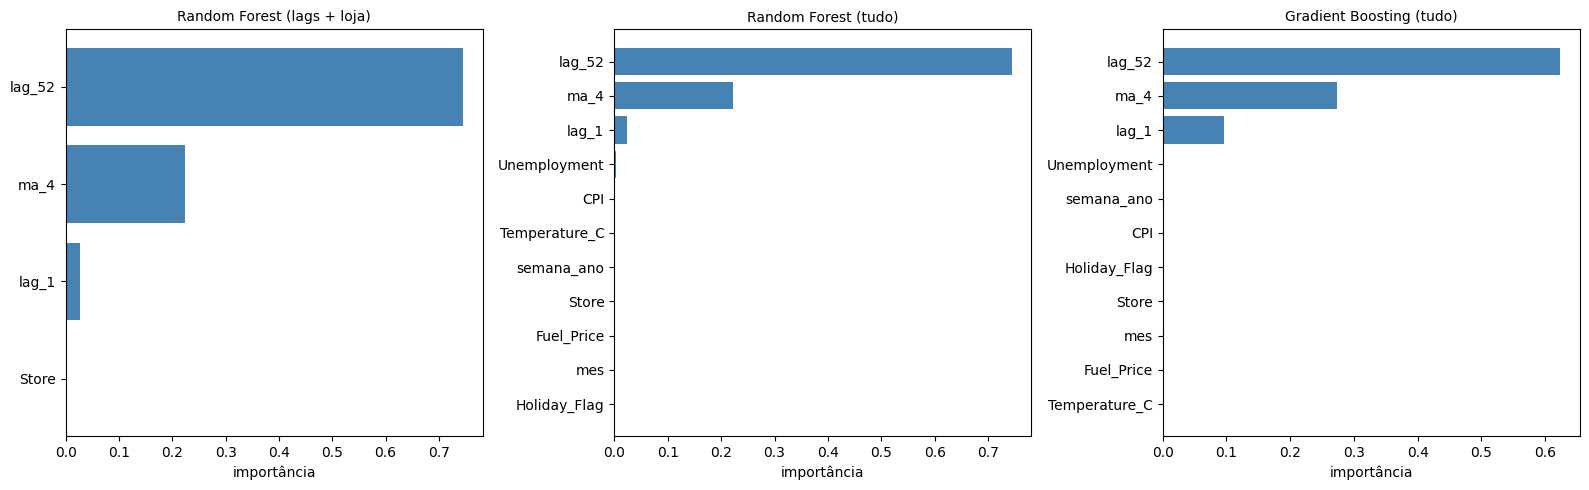

In [34]:
# Importância nativa das árvores nos 3 modelos mais relevantes
nomes = ["Random Forest (lags + loja)", "Random Forest (tudo)", "Gradient Boosting (tudo)"]

fig, axes = plt.subplots(1, len(nomes), figsize=(16, 5))
for ax, nome in zip(axes, nomes):
    modelo, feats = modelos[nome]
    imp = pd.Series(modelo.feature_importances_, index=feats).sort_values()
    ax.barh(imp.index, imp.values, color="steelblue")
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel("importância")
plt.tight_layout()
plt.show()

### Conclusões da Etapa 7
- **Resultados (WAPE no teste):** Random Forest (lags + loja) 4,3% · Gradient Boosting (lags + loja) 4,4% · Random Forest (tudo) 4,3% · Gradient Boosting (tudo) 4,5%. Referência: regressão linear 4,5% e baseline 5,6%.
- **Campeão provisório:** Random Forest (lags + loja), MAE US$ 45,0 mil. O ganho sobre a regressão linear é de 0,2 p.p. (~US$ 2,2 mil por loja por semana), pequeno para um único teste de 30 semanas. Serão comparados de novo na Etapa 9.
- **Variáveis externas continuam sem ajudar, mesmo com modelos não lineares:** na Random Forest, "tudo" empata com "lags + loja"; no Gradient Boosting, piora (4,5% contra 4,4%). A conclusão da Etapa 6 não vem de uma limitação do modelo linear.
- **Importância das features (nativa):** `lag_52` domina (0,62 a 0,75), seguido de `ma_4` (0,22 a 0,27). `lag_1`, `Store`, externas e calendário ficam perto de zero (o `lag_1` chega a ~0,10 no Gradient Boosting). A ordem é a mesma dos coeficientes da regressão linear: árvores e regressão aprenderam essencialmente "ano passado + nível recente".
- **`Store` sem importância:** o tamanho da loja já está embutido nos lags.
- **Ressalvas:** a importância nativa divide o crédito entre features correlacionadas (`lag_1` e `ma_4`) e não mede se a variável melhora o teste; usar permutação na Etapa 11. Hiperparâmetros padrão, sem ajuste.

## Etapa 8 · Rede neural simples (MLP)

Objetivo: cumprir a comparação clássico vs rede neural pedida no enunciado.

**MLP:** camadas de neurônios treinadas por descida do gradiente. **Normalização obrigatória:** features e alvo em escalas enormes desequilibram o gradiente. O `Pipeline` aprende média e desvio só no treino.

**Regras:** só `lag_1`, `lag_52` e `ma_4`; no máximo 3 configurações; sem `early_stopping`; semente fixa.

### 8a · MLP com lags

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
import warnings
from sklearn.exceptions import ConvergenceWarning

tr_mlp = treino.dropna(subset=feat_lags)  # mesmas 2.745 linhas de sempre

configs = {"MLP (16)": (16,), "MLP (64)": (64,), "MLP (64, 32)": (64, 32)}
mlps = {}

for nome, camadas in configs.items():
    # Features normalizadas no Pipeline; alvo normalizado pelo TransformedTargetRegressor
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=camadas, max_iter=2000, random_state=42)),
    ])
    modelo = TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(tr_mlp[feat_lags], tr_mlp["Weekly_Sales"])
    mlps[nome] = modelo
    registrar(nome + " (lags)", y_teste, modelo.predict(teste[feat_lags]))
    n_iter = modelo.regressor_.named_steps["mlp"].n_iter_
    print(f"{nome}: {n_iter} iterações | não convergiu: {len(avisos) > 0}")

resultados.style.format({"MAE": "{:,.0f}", "WAPE": "{:.1%}"})

MLP (16): 63 iterações | não convergiu: False
MLP (64): 20 iterações | não convergiu: False
MLP (64, 32): 35 iterações | não convergiu: False


,modelo,MAE,WAPE
0,Baseline: repete semana passada (lag_1),"58,628",5.6%
1,Baseline: repete ano passado (lag_52),"59,274",5.7%
2,Regressão linear (lags),"47,158",4.5%
3,Linear: lags + externas,"47,585",4.6%
4,Linear: lags + calendário (mês),"51,562",4.9%
5,Linear: lags + externas + calendário,"50,295",4.8%
6,Random Forest (lags + loja),"44,992",4.3%
7,Gradient Boosting (lags + loja),"45,605",4.4%
8,Random Forest (tudo),"45,055",4.3%
9,Gradient Boosting (tudo),"47,166",4.5%


### Conclusões da Etapa 8
- **Resultados (só lags, WAPE no teste):** MLP (16) 4,5% · MLP (64) 4,4% · MLP (64, 32) 4,3% (MAE US$ 44,4 mil, o menor da tabela). Os três convergiram.
- **Clássico vs rede neural:** o MLP (64, 32) empata com a Random Forest (lags + loja) em WAPE (4,3%), e a diferença de MAE (~US$ 600 por loja por semana) é ruído. A regressão linear (4,5%) também fica muito próxima.
- **Sem ordem clara entre arquiteturas:** uma só semente e 2.745 linhas de treino; a ordem pode mudar com outra semente. Nenhuma configuração foi ajustada olhando o teste.
- **Cuidados técnicos:** features normalizadas no `Pipeline` e alvo normalizado com `TransformedTargetRegressor`; sem `early_stopping` (ignoraria a ordem do tempo).
- **Explicabilidade vs ganho:** o ganho (≤ 0,2 p.p.) não compensa a perda de explicabilidade. A regressão linear permite dizer à logística "72% ano passado + 29% nível recente"; o MLP não tem leitura direta (parte dela pode ser recuperada por permutação na Etapa 11), exige normalização, depende de semente e é mais frágil de manter.
- **Lição:** linear, árvores e MLP ficam entre 4,3% e 4,5%. O valor está na informação (lags), não na complexidade do modelo.

## Etapa 9 · Validação mais robusta e comparação final

Objetivo: garantir que o campeão não ganhou por sorte do período de teste.

**Walk-forward:** treina até a semana X, testa as próximas 13, avança e repete.

**Atenção (painel):** o `TimeSeriesSplit` corta por linhas; como o df está ordenado por loja, o corte é feito sobre as **datas distintas**.

### 9a · Janelas e validação

In [36]:
from sklearn.model_selection import TimeSeriesSplit

# Corte sobre as DATAS (não sobre as linhas): só semanas com todos os lags disponíveis
datas_c = np.sort(df.dropna(subset=feat_lags)["Date"].unique())
print("Semanas completas:", len(datas_c), "|", pd.Timestamp(datas_c[0]).date(), "→", pd.Timestamp(datas_c[-1]).date())

tscv = TimeSeriesSplit(n_splits=4, test_size=13)
folds = []
for k, (i_tr, i_te) in enumerate(tscv.split(datas_c), start=1):
    d_tr, d_te = datas_c[i_tr], datas_c[i_te]
    assert d_tr.max() < d_te.min()  # treino sempre antes do teste
    folds.append((d_tr, d_te))
    print(f"Janela {k}: treino {len(d_tr)} semanas (até {pd.Timestamp(d_tr.max()).date()}) | "
          f"teste {pd.Timestamp(d_te.min()).date()} → {pd.Timestamp(d_te.max()).date()}")

Semanas completas: 91 | 2011-02-04 → 2012-10-26
Janela 1: treino 39 semanas (até 2011-10-28) | teste 2011-11-04 → 2012-01-27
Janela 2: treino 52 semanas (até 2012-01-27) | teste 2012-02-03 → 2012-04-27
Janela 3: treino 65 semanas (até 2012-04-27) | teste 2012-05-04 → 2012-07-27
Janela 4: treino 78 semanas (até 2012-07-27) | teste 2012-08-03 → 2012-10-26


In [37]:
# Os 4 candidatos: cada um é uma função que cria um modelo novo (None = baseline sem treino)
def novo_mlp():
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=42))])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

candidatos = {
    "Baseline lag_52": (None, feat_lags),
    "Regressão linear (lags)": (lambda: LinearRegression(), feat_lags),
    "Random Forest (lags + loja)": (lambda: RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), feat_lags + ["Store"]),
    "MLP (64, 32)": (novo_mlp, feat_lags),
}

partes = []
for k, (d_tr, d_te) in enumerate(folds, start=1):
    tr = df[df["Date"].isin(d_tr)].dropna(subset=feat_lags)
    te = df[df["Date"].isin(d_te)]
    for nome, (fabrica, feats) in candidatos.items():
        if fabrica is None:
            pred = te["lag_52"].values
        else:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                pred = fabrica().fit(tr[feats], tr["Weekly_Sales"]).predict(te[feats])
        partes.append(pd.DataFrame({"modelo": nome, "janela": k, "Store": te["Store"].values,
                                    "Date": te["Date"].values, "Holiday_Flag": te["Holiday_Flag"].values,
                                    "y": te["Weekly_Sales"].values, "pred": pred}))

pred_cv = pd.concat(partes, ignore_index=True)
print("Previsões guardadas:", len(pred_cv), "(esperado:", 4 * 4 * 13 * 45, ")")

Previsões guardadas: 9360 (esperado: 9360 )


In [38]:
# WAPE por janela, com média e desvio entre janelas
def wape_df(d):
    return np.sum(np.abs(d["y"] - d["pred"])) / np.sum(d["y"])

tab = pred_cv.groupby(["modelo", "janela"]).apply(wape_df, include_groups=False).unstack("janela")
tab.columns = [f"Janela {c}" for c in tab.columns]
tab["Média"] = tab.mean(axis=1)
tab["Desvio"] = tab.drop(columns="Média").std(axis=1)
tab.sort_values("Média").style.format("{:.1%}")

,Janela 1,Janela 2,Janela 3,Janela 4,Média,Desvio
modelo,,,,,,
Baseline lag_52,5.5%,6.3%,5.2%,5.1%,5.6%,0.5%
"MLP (64, 32)",10.1%,5.1%,3.7%,3.7%,5.6%,3.0%
Random Forest (lags + loja),11.0%,5.1%,3.7%,3.8%,5.9%,3.5%
Regressão linear (lags),10.4%,5.5%,4.0%,3.8%,5.9%,3.1%


### 9b · Onde os modelos erram: picos, viés, lojas e feriados

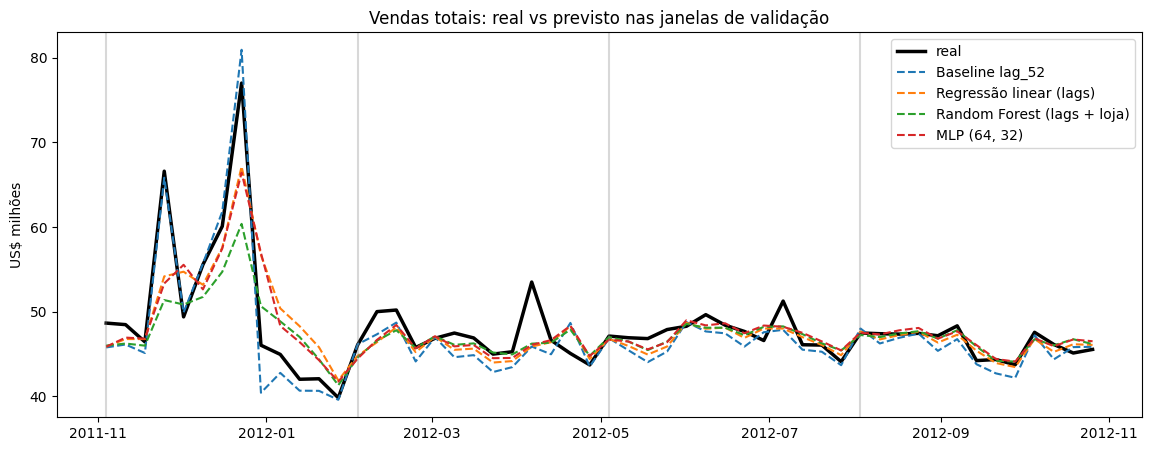

In [39]:
# Vendas totais da rede nas 52 semanas de teste: real vs previsto por modelo
tot = pred_cv.groupby(["modelo", "Date"])[["y", "pred"]].sum() / 1e6
real = tot.xs("Baseline lag_52", level="modelo")["y"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(real.index, real.values, color="black", linewidth=2.5, label="real")
for nome in candidatos:
    s = tot.xs(nome, level="modelo")["pred"]
    ax.plot(s.index, s.values, linestyle="--", label=nome)
for _, d_te in folds:
    ax.axvline(pd.Timestamp(d_te.min()), color="gray", alpha=0.3)  # início de cada janela
ax.set_title("Vendas totais: real vs previsto nas janelas de validação")
ax.set_ylabel("US$ milhões")
ax.legend()
plt.show()

In [40]:
# Viés com sinal: (previsto - real) / real. Negativo = o modelo subestima as vendas
def vies(d):
    return (d["pred"].sum() - d["y"].sum()) / d["y"].sum()

pred_cv.groupby(["modelo", "janela"]).apply(vies, include_groups=False).unstack("janela").style.format("{:+.1%}")

janela,1,2,3,4
modelo,,,,
Baseline lag_52,-1.8%,-3.3%,-2.5%,-1.5%
"MLP (64, 32)",-0.7%,-2.2%,-0.4%,+0.7%
Random Forest (lags + loja),-4.1%,-2.1%,-0.6%,+0.3%
Regressão linear (lags),+0.3%,-2.7%,-1.2%,-0.3%


In [41]:
# WAPE por loja (média das 4 janelas): as 5 piores, para a regressão linear e o baseline
for nome in ["Regressão linear (lags)", "Baseline lag_52"]:
    d = pred_cv[pred_cv["modelo"] == nome]
    por_loja = d.groupby("Store").apply(wape_df, include_groups=False).sort_values(ascending=False)
    print(nome, "| 5 piores lojas:", {int(k): f"{v:.1%}" for k, v in por_loja.head(5).items()},
          "| mediana:", f"{por_loja.median():.1%}")

# Semanas de feriado (1) vs normais (0), todas as janelas
print()
pred_cv.groupby(["modelo", "Holiday_Flag"]).apply(wape_df, include_groups=False).unstack().map("{:.1%}".format)

Regressão linear (lags) | 5 piores lojas: {36: '14.2%', 14: '9.6%', 38: '8.0%', 39: '7.9%', 35: '7.7%'} | mediana: 5.9%
Baseline lag_52 | 5 piores lojas: {36: '22.0%', 38: '12.7%', 39: '10.1%', 14: '10.1%', 44: '9.9%'} | mediana: 5.2%



Holiday_Flag,0,1
modelo,,
Baseline lag_52,5.4%,6.8%
"MLP (64, 32)",5.0%,14.1%
Random Forest (lags + loja),5.4%,12.7%
Regressão linear (lags),5.3%,13.8%


### 9c · Lojas difíceis e abordagem híbrida

**Atenção:** a regra do híbrido foi definida depois de ver os resultados das janelas, com um único pico de fim de ano. É evidência fraca, não confirmação.

In [42]:
# O que as lojas difíceis têm de diferente? Tamanho, variabilidade (CV) e força do pico
piores = [36, 14, 38, 39, 35]
perfil = df.groupby("Store")["Weekly_Sales"].agg(media="mean", desvio="std", maximo="max")
perfil["CV (desvio/média)"] = perfil["desvio"] / perfil["media"]
perfil["pico (máx/média)"] = perfil["maximo"] / perfil["media"]
perfil["grupo"] = np.where(perfil.index.isin(piores), "piores", "demais")

perfil.groupby("grupo")[["media", "CV (desvio/média)", "pico (máx/média)"]].median().round(2)

,media,CV (desvio/média),pico (máx/média)
grupo,,,
demais,"984,846.70",0.13,1.74
piores,"919,724.98",0.16,1.76


In [43]:
# Híbrido: regressão linear nas semanas normais, lag_52 de 15/nov a 31/dez (regra ex-post!)
wide = pred_cv.pivot_table(index=["janela", "Store", "Date"], columns="modelo", values="pred")
wide["y"] = pred_cv[pred_cv["modelo"] == "Baseline lag_52"].set_index(["janela", "Store", "Date"])["y"]

d = wide.index.get_level_values("Date")
pico = ((d.month == 11) & (d.day >= 15)) | (d.month == 12)
wide["Híbrido (linear + lag_52 no pico)"] = np.where(pico, wide["Baseline lag_52"], wide["Regressão linear (lags)"])

cols = ["Baseline lag_52", "Regressão linear (lags)", "Híbrido (linear + lag_52 no pico)"]
erro_abs = {c: (wide[c] - wide["y"]).abs().groupby(level="janela").sum() / wide["y"].groupby(level="janela").sum() for c in cols}
tab_h = pd.DataFrame(erro_abs).T
tab_h.columns = [f"Janela {c}" for c in tab_h.columns]
tab_h["Média"] = tab_h.mean(axis=1)
print("Semanas de pico na validação:", wide.index.get_level_values("Date")[pico].nunique())
tab_h.style.format("{:.1%}")

Semanas de pico na validação: 7


,Janela 1,Janela 2,Janela 3,Janela 4,Média
Baseline lag_52,5.5%,6.3%,5.2%,5.1%,5.6%
Regressão linear (lags),10.4%,5.5%,4.0%,3.8%,5.9%
Híbrido (linear + lag_52 no pico),7.1%,5.5%,4.0%,3.8%,5.1%


### Conclusões da Etapa 9
- **Validação:** walk-forward com 4 janelas de 13 semanas (de 04/11/2011 a 26/10/2012), cortadas sobre as datas (e não sobre as linhas, por causa do painel). A janela 1 cobre Thanksgiving e Natal de 2011 e foi treinada só com semanas sem pico (39 semanas, até 28/10/2011).
- **WAPE médio (desvio entre janelas):** Baseline `lag_52` 5,6% (0,5%) · MLP (64, 32) 5,6% (3,0%) · Random Forest 5,9% (3,5%) · Regressão linear 5,9% (3,1%). Na média, os modelos empatam com o baseline, e a diferença entre eles é menor que o desvio: não dá para eleger um campeão entre os três.
- **Janela do Natal:** o baseline (5,5%) ganha dos modelos (10,1% a 11,0%) por quase 2×. Nas janelas calmas (3 e 4), os modelos (3,7% a 4,0%) ganham do baseline (5,1% a 5,2%). O campeão da Etapa 7 só valia para períodos sem pico.
- **Causa do erro no pico:** os modelos achatam o pico (Natal previsto ~67 contra 77 real) e "arrastam o eco" depois dele (janeiro previsto ~50 contra 46 real), porque `lag_1` e `ma_4` carregam o pico. O viés líquido é pequeno (−4,1% a +0,3%) porque os dois erros se cancelam, mas o WAPE soma ambos.
- **Feriado vs normal:** os modelos vão de ~5% para 13% a 14% em semanas de feriado; o baseline, de 5,4% para 6,8%.
- **Viés do baseline nas janelas 2 a 4:** negativo (−1,5% a −3,3%), sugerindo crescimento anual de ~2% a 3% que o `lag_52` não enxerga. A Páscoa (06/04/2012) e um pico de julho foram errados por todos.
- **Lojas difíceis:** 36 (14,2% na linear, 22,0% no baseline), 14, 38, 39 e 35. Tamanho, CV (0,16 contra 0,13) e força do pico (1,76 contra 1,74) quase não diferem das demais. A causa fica em aberto.
- **Abordagem híbrida (regressão linear nas semanas normais e `lag_52` de 15/11 a 31/12):** WAPE médio 5,1% (janela 1: 7,1%), a melhor média. **Ressalva:** a regra foi definida depois de ver os resultados, com um único pico de fim de ano, então é evidência fraca. O erro que sobra na janela 1 vem das semanas de janeiro, que ainda usam a linear.
- **Recomendação:** híbrido, com confiança baixa a moderada. Com ~5 anos de histórico, o modelo veria vários picos no treino, o calendário deixaria de decorar um único ano, a regra do híbrido poderia ser validada em picos diferentes e o `lag_52` custaria menos dados.

## Etapa 10 · Versão "vai vender mais ou menos?" (espelho do TCC)

## Etapa 11 · Interpretação e tradução para negócio

Objetivo: transformar números em argumentos para o board.

**Importância por permutação:** embaralha uma coluna do teste por vez e mede quanto o MAE sobe. Mais confiável que a importância nativa das árvores.

**Atenção:** `lag_1` e `ma_4` são correlacionadas, então a importância de cada uma fica subestimada.

### 11a · Importância por permutação

Regressão linear (lags) -> {'lag_52': '391.3 mil', 'ma_4': '64.1 mil', 'lag_1': '47.7 mil'}
Random Forest (lags + loja) -> {'lag_52': '449.6 mil', 'ma_4': '44.3 mil', 'lag_1': '20.5 mil', 'Store': '4.4 mil'}


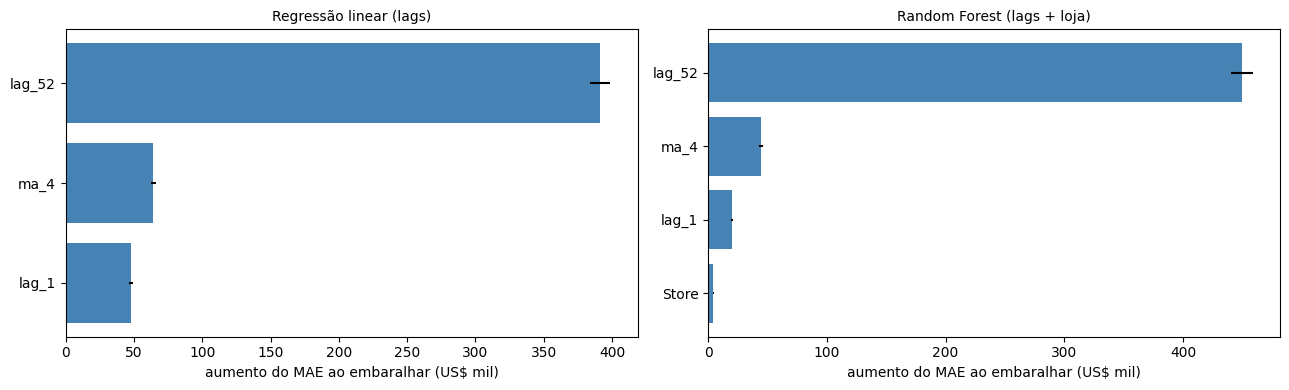

In [44]:
from sklearn.inspection import permutation_importance

# Split original da Etapa 4 (treino até 30/03/2012, teste abr–out/2012)
alvos = {
    "Regressão linear (lags)": (modelo_lin, feat_lags),
    "Random Forest (lags + loja)": modelos["Random Forest (lags + loja)"],
}

fig, axes = plt.subplots(1, len(alvos), figsize=(13, 4))
for ax, (nome, (modelo, feats)) in zip(axes, alvos.items()):
    r = permutation_importance(modelo, teste[feats], teste["Weekly_Sales"],
                               scoring="neg_mean_absolute_error", n_repeats=10, random_state=42)
    imp = pd.Series(r.importances_mean, index=feats).sort_values()
    ax.barh(imp.index, imp.values / 1e3, xerr=pd.Series(r.importances_std, index=feats)[imp.index] / 1e3, color="steelblue")
    ax.set_title(nome, fontsize=10)
    ax.set_xlabel("aumento do MAE ao embaralhar (US$ mil)")
    print(nome, "->", {k: f"{v / 1e3:,.1f} mil" for k, v in imp.sort_values(ascending=False).items()})
plt.tight_layout()
plt.show()

### 11b · Erro em dólares: híbrido, pico e semanas normais

In [45]:
# Traduz o erro do híbrido (validação das 4 janelas) em US$ por loja por semana
h = "Híbrido (linear + lag_52 no pico)"
err = (wide[h] - wide["y"]).abs()
y = wide["y"]

grupos = {"Todas as semanas": np.ones(len(wide), dtype=bool), "Pico (15/11 a 31/12)": pico, "Semanas normais": ~pico}
resumo = pd.DataFrame({
    "Venda média por loja-semana (US$)": {g: y[m].mean() for g, m in grupos.items()},
    "Erro médio por loja-semana (US$)": {g: err[m].mean() for g, m in grupos.items()},
    "WAPE": {g: err[m].sum() / y[m].sum() for g, m in grupos.items()},
})
display(resumo.style.format({"Venda média por loja-semana (US$)": "{:,.0f}", "Erro médio por loja-semana (US$)": "{:,.0f}", "WAPE": "{:.1%}"}))

# A rede inteira: erros de lojas diferentes se cancelam parcialmente ao somar
rede = wide.groupby(level="Date")[[h, "y"]].sum()
erro_rede = (rede[h] - rede["y"]).abs()
print(f"Rede: erro médio semanal US$ {erro_rede.mean() / 1e6:.2f} mi ({erro_rede.mean() / rede['y'].mean():.1%} da venda semanal)")
print(f"Soma dos erros por loja (o que a logística sente): US$ {err.groupby(level='Date').sum().mean() / 1e6:.2f} mi por semana")

,Venda média por loja-semana (US$),Erro médio por loja-semana (US$),WAPE
Todas as semanas,"1,067,681","54,895",5.1%
Pico (15/11 a 31/12),"1,273,367","72,931",5.7%
Semanas normais,"1,035,685","52,089",5.0%


Rede: erro médio semanal US$ 1.60 mi (3.3% da venda semanal)
Soma dos erros por loja (o que a logística sente): US$ 2.47 mi por semana


### 11c · Como a logística consumiria a previsão: alerta de pico

Regra simples: se a venda **prevista** de uma loja na semana passa de X vezes a sua média das 52 semanas anteriores, dispara o alerta de reforço de estoque. O limite X é decisão de negócio (custo de ruptura contra custo de excesso); aqui mostramos a sensibilidade.

In [46]:
# Nível normal de cada loja: média das 52 semanas ANTERIORES (shift(1): sem a semana atual)
df["media_52"] = df.groupby("Store")["Weekly_Sales"].transform(lambda s: s.shift(1).rolling(52).mean())

av = wide.reset_index().merge(df[["Store", "Date", "media_52"]], on=["Store", "Date"], how="left")
print("Linhas sem média de 52 semanas:", av["media_52"].isna().sum())

linhas = []
for limite in [1.1, 1.2, 1.3]:
    pico_real = av["y"] > limite * av["media_52"]
    for nome in ["Baseline lag_52", "Regressão linear (lags)", "Híbrido (linear + lag_52 no pico)"]:
        alerta = av[nome] > limite * av["media_52"]
        tp = (alerta & pico_real).sum()
        linhas.append({"limite": f"{limite:.1f}x", "modelo": nome, "picos reais": int(pico_real.sum()),
                       "recall": tp / pico_real.sum(), "precisão": tp / max(alerta.sum(), 1)})

pd.DataFrame(linhas).set_index(["limite", "modelo"]).style.format({"recall": "{:.0%}", "precisão": "{:.0%}"})

Linhas sem média de 52 semanas: 0


### 11d · Limitações e riscos

- **Dados proxy dos EUA (Walmart):** 45 lojas em um único país. A Quantum Commerce opera em 12 países, com calendários e picos diferentes (o Natal não é pico em todos). A abordagem foi validada, o desempenho não.
- **Histórico curto:** 143 semanas (2,7 anos), com um único pico de fim de ano na validação e só um ano completo de treino antes dele. Os modelos nunca treinaram com um Natal antes de serem testados nele.
- **Regra do híbrido definida depois de ver os resultados:** evidência fraca; precisa ser validada em outros picos.
- **Granularidade:** previsão por loja e semana, sem produto, categoria ou região, que o desafio do enunciado cita. Com 5 milhões de SKUs, a previsão por SKU é outro problema.
- **Variáveis externas:** não ajudaram, e no teste foram usadas com os valores reais da semana (cenário otimista; na prática seriam previsões).
- **Feriados móveis:** a Páscoa desloca o pico entre anos e o `lag_52` alinha pela semana, e não pelo evento. A `Holiday_Flag` do dataset também é imprecisa (a flag de Natal cai na semana depois do pico).
- **Crescimento anual:** o `lag_52` não enxerga o crescimento de ~2% a 3% ao ano sugerido pelo viés do baseline.
- **Lojas com erro persistente (36, 14, 38, 39 e 35):** causa desconhecida.
- **Ganho modesto sobre a regra simples:** 5,1% contra 5,6% de WAPE médio; o valor principal é operacional.
- **Sem custos reais:** não temos o custo de ruptura nem de excesso de estoque, então o impacto financeiro do erro não pôde ser calculado.
- **Operação:** sem monitoramento de desvio nem rotina de retreino definidos.
- **Evolução futura (fora do escopo desta disciplina):** redes recorrentes e Transformers podem ser exploradas depois, só como próximo passo.

### Conclusões da Etapa 11
- **Importância por permutação (aumento do MAE, base ≈ US$ 47 mil):** `lag_52` +391 mil (linear) e +450 mil (Random Forest); `ma_4` +64 mil e +44 mil; `lag_1` +48 mil e +20 mil; `Store` +4 mil (pequena, mas não nula). Sem o `lag_52`, o erro sobe de 8 a 10 vezes.
- **Erro do híbrido em dólares (validação, 4 janelas):** US$ 54,9 mil por loja-semana em US$ 1,07 mi (WAPE 5,1%). No pico: US$ 72,9 mil em US$ 1,27 mi (5,7%); nas semanas normais: US$ 52,1 mil em US$ 1,04 mi (5,0%). O erro em dólares no pico é ~40% maior por loja.
- **Rede contra lojas:** o erro da rede é US$ 1,60 mi por semana (3,3%); a soma dos erros por loja, que a logística sente, é US$ 2,47 mi por semana.
- **Alerta de pico (previsto > X × média das 52 semanas anteriores):** em 1,2×, o híbrido pega 82% dos picos reais com 92% de precisão (a regressão linear sozinha: 56% e 68%); em 1,3×, 89% e 91%; em 1,1×, 55% e 82%. O limite define também o que conta como pico real, então a tabela não é um trade-off simples. Com 1,1× entram altas de 10% a 20%, dentro do ruído do modelo (~5%).
- **Limite sugerido: 1,2×.** Cobre ~121 picos reais com ~10 alarmes falsos, contra ~86 picos em 1,3× com ~9 falsos. O limite final é decisão de negócio (custo de ruptura contra custo de excesso, ainda não levantado), e os números vêm de um único pico de fim de ano.
- **Em 3 frases para o board:** (1) o modelo estima as vendas semanais de cada loja pelo que ela vendeu na mesma semana do ano passado e nas últimas semanas, e usa o ano anterior como referência nos picos de fim de ano; (2) erra em média ~5% por loja (~US$ 55 mil em US$ 1,07 mi por semana), um pouco menos que a regra simples, com erro em dólares maior no pico; (3) permite à logística abastecer e escalar cada loja com antecedência, e o ganho financeiro depende de custos de ruptura e de excesso ainda por levantar.

## Etapa 12 · Documento final